Homework 3, problem 1, part c

In [3]:
import numpy as np
import matplotlib.pyplot as plt

In [4]:
def compute_rotation_number(I, epsilon, total_time=300, transient_time=100, dt=0.005):
    t = 0.0
    v = 0.0
    spike_count = 0
    
    # time steps
    total_steps = int(total_time / dt)
    transient_steps = int(transient_time / dt)
    
    exp_dt = np.exp(-dt)
    
    for step in range(total_steps):
        drive = I + epsilon * np.sin(2 * np.pi * t)
        
        v = v * exp_dt + drive * (1 - exp_dt)
        t += dt
        
        if v >= 1.0: # threshold crossing condition
            v = 0.0  # reset potential
            if step >= transient_steps:
                spike_count += 1
                
    forcing_periods = (total_time - transient_time) * 1.0
    return spike_count / forcing_periods

In [5]:
# parameters
epsilon = 0.5
I_grid = np.linspace(1.2, 2.2, 200)
rotation_numbers = []

for I in I_grid:
    rot_num = compute_rotation_number(I, epsilon)
    rotation_numbers.append(rot_num)

# theoretical calculations
I_star = 1.0 / (1.0 - np.exp(-1.0))  # ~1.5820
half_width = epsilon / np.sqrt(1.0 + 4 * np.pi**2)
lower_bound = I_star - half_width
upper_bound = I_star + half_width

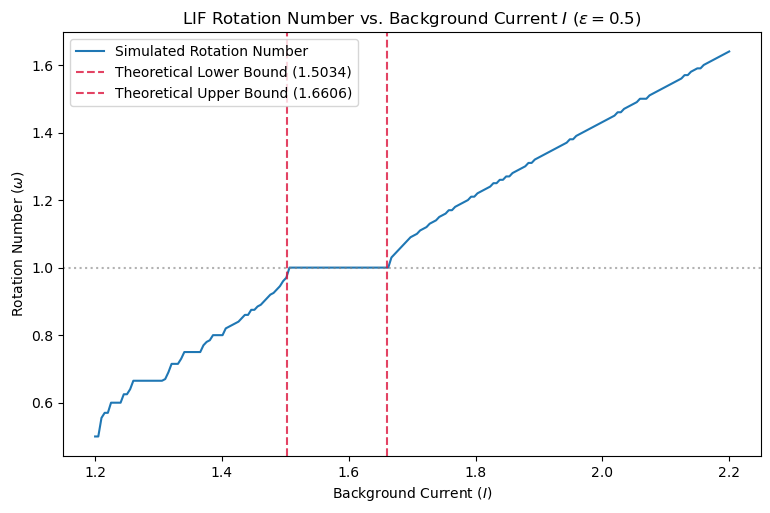

In [6]:
plt.figure(figsize=(9, 5.5))
plt.plot(I_grid, rotation_numbers, label="Simulated Rotation Number")

# boundaries of the 1:1 phase-locking zone
plt.axvline(lower_bound, color="crimson", linestyle="--", alpha=0.8, label=f"Theoretical Lower Bound ({lower_bound:.4f})")
plt.axvline(upper_bound, color="crimson", linestyle="--", alpha=0.8, label=f"Theoretical Upper Bound ({upper_bound:.4f})")
plt.axhline(1.0, color="gray", linestyle=":", alpha=0.6)

plt.title(f"LIF Rotation Number vs. Background Current $I$ ($\epsilon = {epsilon}$)")
plt.xlabel("Background Current ($I$)")
plt.ylabel("Rotation Number ($\omega$)")
plt.legend(loc="upper left")

plt.show()